# Estudio 2 — Parámetros que nadie tuvo en cuenta

**Pregunta:** en el modelo hay decisiones que los papers no discuten o que tomaron sin probarlas. ¿Alguna cambia mucho el comportamiento?

**Cómo:** base = A4 (Puckett) con 20 peces y 1 BL/s. Cambiamos **una sola cosa a la vez** y corremos las 10 seeds. Las opciones nuevas están en `study_model.py` y cada una tiene su prueba en `test_study_model.py` (pruebas 5–10). Con sus valores por defecto, el modelo da exactamente lo mismo que `shiner_model.py` (prueba 1).

El plan completo está en el [README](README.md).

## Preparación

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the parameter_studies folder (the one with study_tools.py) and let Python import from it.
TOOLS_FOLDER = Path.cwd()
while not (TOOLS_FOLDER / "study_tools.py").is_file():
    if TOOLS_FOLDER == TOOLS_FOLDER.parent:
        raise FileNotFoundError("study_tools.py was not found in this folder or any parent folder.")
    TOOLS_FOLDER = TOOLS_FOLDER.parent
if str(TOOLS_FOLDER) not in sys.path:
    sys.path.insert(0, str(TOOLS_FOLDER))

import study_tools
from study_tools import (
    PUCKETT_SETTINGS, STUDY_2_DEFAULTS, A0_COLOR, PUCKETT_COLOR, EXTRA_COLOR,
    change_settings, final_label_counts, run_many, short_table, summarize,
)

# Where this study keeps its results and figures.
STUDY_FOLDER = TOOLS_FOLDER / "02_parametros_nuevos"
DATA_FOLDER = STUDY_FOLDER / "data"
FIGURE_FOLDER = STUDY_FOLDER / "figures"
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

SEEDS = list(range(10))
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Las configuraciones

Cada configuración guarda qué parámetro cambia (`parameter`) y a qué valor (`value`).

- **Inicio "25 % central":** los peces empiezan en un cuadrado central cuyo **lado** es el 25 % del lado de la arena (7 × 7 BL en la arena de 28 BL). Es nuestra lectura de "el 25 % central"; está fijada antes de correr.
- **8b (extra, no está en el README):** como el 8, pero sin la "zona muda" entre la repulsión y la atracción (r_o = 0.51 BL). Al apagar la orientación, la zona de 0.5 a 3 BL deja de provocar reacciones de dirección; en 8b la atracción empieza en 0.51 BL, como en el "swarm" de Couzin. La regulación de velocidad usa a todos los vecinos dentro de 5.5 BL en los dos casos.

In [2]:
base = change_settings(PUCKETT_SETTINGS, "base (A4)", STUDY_2_DEFAULTS)
base["parameter"] = "base"
base["value"] = "base"


def variant(number, parameter, value, changes):
    """The base configuration with some changes, labelled with its parameter and value."""
    settings = change_settings(base, f"{number}. {parameter}: {value}", changes)
    settings["parameter"] = parameter
    settings["value"] = value
    return settings


study_2_runs = [base]
study_2_runs.append(variant(1, "tamaño de arena", "20", {"arena": 20.0}))
study_2_runs.append(variant(1, "tamaño de arena", "40", {"arena": 40.0}))
study_2_runs.append(variant(2, "inicio", "25 % central", {"initial_spread": 0.25}))
study_2_runs.append(variant(3, "orden de actualización", "uno por uno", {"update": "asynchronous"}))
study_2_runs.append(variant(4, "vecinos", "k = 4", {"neighbour_mode": "topological", "k_neighbours": 4}))
study_2_runs.append(variant(4, "vecinos", "k = 7", {"neighbour_mode": "topological", "k_neighbours": 7}))
study_2_runs.append(variant(5, "combinación", "normalizada", {"social_combination": "normalized"}))
study_2_runs.append(variant(6, "velocidad propia de cada pez", "10 %", {"speed_sd": 0.1}))
study_2_runs.append(variant(6, "velocidad propia de cada pez", "30 %", {"speed_sd": 0.3}))
study_2_runs.append(variant(7, "regulación de velocidad", "ganancia 0.1", {"speed_gain": 0.1}))
study_2_runs.append(variant(7, "regulación de velocidad", "ganancia 0.3", {"speed_gain": 0.3}))
for gain in [0.0, 0.1, 0.3]:
    changes = {"rules": "repulsion+attraction", "speed_gain": gain}
    study_2_runs.append(variant(8, "sin orientación + regulación", f"ganancia {gain:g}", changes))
for gain in [0.0, 0.1, 0.3]:
    changes = {"rules": "repulsion+attraction", "speed_gain": gain, "orientation_radius": 0.51}
    study_2_runs.append(variant("8b", "sin orientación + regulación, sin hueco", f"ganancia {gain:g}", changes))

for settings in study_2_runs:
    print(settings["label"])

base (A4)
1. tamaño de arena: 20
1. tamaño de arena: 40
2. inicio: 25 % central
3. orden de actualización: uno por uno
4. vecinos: k = 4
4. vecinos: k = 7
5. combinación: normalizada
6. velocidad propia de cada pez: 10 %
6. velocidad propia de cada pez: 30 %
7. regulación de velocidad: ganancia 0.1
7. regulación de velocidad: ganancia 0.3
8. sin orientación + regulación: ganancia 0
8. sin orientación + regulación: ganancia 0.1
8. sin orientación + regulación: ganancia 0.3
8b. sin orientación + regulación, sin hueco: ganancia 0
8b. sin orientación + regulación, sin hueco: ganancia 0.1
8b. sin orientación + regulación, sin hueco: ganancia 0.3


Corremos las 18 configuraciones con 10 seeds (180 simulaciones).

In [3]:
results = run_many(study_2_runs, SEEDS, DATA_FOLDER / "results.csv")
summary = summarize(results, ["label", "parameter", "value"])

Loaded saved results from results.csv (set study_tools.RERUN = True to simulate again).


Comprobación: la base de este estudio es la misma configuración y las mismas seeds que la base del estudio 4, así que tiene que dar exactamente lo mismo.

In [4]:
STUDY_4_CSV = TOOLS_FOLDER / "04_minimo_y_sensibilidad" / "data" / "part_b_sensitivity.csv"
if STUDY_4_CSV.exists():
    study_4 = study_tools.load_results(STUDY_4_CSV)
    theirs = study_4[study_4["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
    ours = results[results["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
    assert np.array_equal(theirs, ours)
    print("Check passed: study 2 base = study 4 base, seed by seed.")
else:
    print("Study 4 results not found; check skipped.")

Check passed: study 2 base = study 4 base, seed by seed.


## Resultados

In [5]:
table = short_table(summary)
table["largest group"] = study_tools.mean_and_error_text(summary, "largest_group_fraction")
table["distance to centre (BL)"] = study_tools.mean_and_error_text(summary, "centroid_distance")
table

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL),largest group,distance to centre (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01,0.93 ± 0.03,3.02 ± 0.87
1,1. tamaño de arena: 20,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01,0.99 ± 0.00,1.24 ± 0.06
2,1. tamaño de arena: 40,4/10,0.86 ± 0.04,0.26 ± 0.08,0.73 ± 0.13,0.53 ± 0.15,0.00 ± 0.00,0.28 ± 0.01,0.84 ± 0.06,5.28 ± 1.49
3,2. inicio: 25 % central,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01,1.00 ± 0.00,1.13 ± 0.01
4,3. orden de actualización: uno por uno,6/10,0.83 ± 0.07,0.20 ± 0.08,0.61 ± 0.01,0.71 ± 0.14,0.00 ± 0.00,0.38 ± 0.01,0.88 ± 0.06,3.64 ± 1.27
5,4. vecinos: k = 4,6/10,0.78 ± 0.10,0.25 ± 0.11,0.62 ± 0.01,0.68 ± 0.14,0.00 ± 0.00,0.27 ± 0.02,0.87 ± 0.06,4.46 ± 1.55
6,4. vecinos: k = 7,6/10,0.90 ± 0.03,0.26 ± 0.08,0.75 ± 0.08,0.66 ± 0.15,0.00 ± 0.00,0.29 ± 0.01,0.90 ± 0.04,3.28 ± 0.89
7,5. combinación: normalizada,7/10,0.85 ± 0.06,0.20 ± 0.10,0.62 ± 0.03,0.78 ± 0.13,0.00 ± 0.00,0.28 ± 0.01,0.92 ± 0.04,3.27 ± 1.26
8,6. velocidad propia de cada pez: 10 %,8/10,0.84 ± 0.06,0.19 ± 0.09,0.68 ± 0.03,0.80 ± 0.13,0.00 ± 0.00,0.28 ± 0.01,0.94 ± 0.05,2.44 ± 0.88
9,6. velocidad propia de cada pez: 30 %,9/10,0.81 ± 0.01,0.12 ± 0.01,0.79 ± 0.07,0.96 ± 0.03,0.01 ± 0.00,0.22 ± 0.01,0.98 ± 0.01,1.70 ± 0.11


In [6]:
final_label_counts(results)

label_final,polarized,milling,swarm,fragmented
label,,,,
base (A4),6,0,0,4
1. tamaño de arena: 20,9,0,0,1
1. tamaño de arena: 40,4,0,0,6
2. inicio: 25 % central,10,0,0,0
3. orden de actualización: uno por uno,6,0,0,4
4. vecinos: k = 4,6,0,0,4
4. vecinos: k = 7,6,0,0,4
5. combinación: normalizada,7,0,0,3
6. velocidad propia de cada pez: 10 %,8,0,0,2


## ¿Es relevante? (criterio del README, fijado antes de correr)

Comparamos cada valor con su referencia: la **base** para los parámetros 1–7, y **"ganancia 0" del mismo grupo** para el 8 y el 8b (así vemos qué agrega la regulación de velocidad cuando no hay orientación).

Un cambio cuenta si pasa al menos una de estas cosas:

- cambia el veredicto "funciona en más de la mitad de las seeds";
- la polarización, la rotación o la fracción del grupo más grande cambian más de 0.1;
- la distancia al vecino o al centro cambian más de un 20 %.

**Además**, el cambio tiene que ser mayor que el doble de su error estándar: √(EE_referencia² + EE_valor²).

In [7]:
UNIT_METRICS = ["polarization", "rotation", "largest_group_fraction"]
DISTANCE_METRICS = ["nnd", "centroid_distance"]


def error_of_difference(reference, row, metric):
    """Standard error of the difference between two configurations."""
    return np.sqrt(reference[metric + "_se"] ** 2 + row[metric + "_se"] ** 2)


def what_changed(reference, row):
    """List of the changes that make this value relevant (empty list = not relevant)."""
    reasons = []

    works_change = row["works"] - reference["works"]
    verdict_changes = (reference["works"] > 0.5) != (row["works"] > 0.5)
    if verdict_changes and abs(works_change) > 2 * error_of_difference(reference, row, "works"):
        reasons.append(f"funciona: {reference['works']:.0%} -> {row['works']:.0%}")

    for metric in UNIT_METRICS:
        change = row[metric] - reference[metric]
        if abs(change) > 0.1 and abs(change) > 2 * error_of_difference(reference, row, metric):
            reasons.append(f"{metric} {change:+.2f}")

    for metric in DISTANCE_METRICS:
        change = row[metric] - reference[metric]
        relative = change / reference[metric]
        if abs(relative) > 0.2 and abs(change) > 2 * error_of_difference(reference, row, metric):
            reasons.append(f"{metric} {relative:+.0%}")
    return reasons


def reference_for(row):
    """The base for parameters 1-7; "ganancia 0" of the same group for 8 and 8b."""
    if row["parameter"].startswith("sin orientación"):
        same_group = summary[(summary["parameter"] == row["parameter"]) & (summary["value"] == "ganancia 0")]
        return same_group.iloc[0]
    return summary[summary["parameter"] == "base"].iloc[0]


relevance_rows = []
for index in range(len(summary)):
    row = summary.iloc[index]
    if row["parameter"] == "base" or row["value"] == "ganancia 0":
        continue
    reasons = what_changed(reference_for(row), row)
    relevance_rows.append({
        "parameter": row["parameter"],
        "value": row["value"],
        "relevant": len(reasons) > 0,
        "what changed": "; ".join(reasons),
    })

relevance = pd.DataFrame(relevance_rows)
relevance

,parameter,value,relevant,what changed
0,tamaño de arena,20,True,centroid_distance -59%
1,tamaño de arena,40,False,
2,inicio,25 % central,True,centroid_distance -62%
3,orden de actualización,uno por uno,False,
4,vecinos,k = 4,False,
5,vecinos,k = 7,False,
6,combinación,normalizada,False,
7,velocidad propia de cada pez,10 %,False,
8,velocidad propia de cada pez,30 %,True,nnd +31%
9,regulación de velocidad,ganancia 0.1,False,


Un parámetro es relevante si al menos uno de sus valores lo es:

In [8]:
parameter_rows = []
for parameter in relevance["parameter"].unique():
    rows = relevance[relevance["parameter"] == parameter]
    parameter_rows.append({"parameter": parameter, "relevant": rows["relevant"].any()})
pd.DataFrame(parameter_rows)

,parameter,relevant
0,tamaño de arena,True
1,inicio,True
2,orden de actualización,False
3,vecinos,False
4,combinación,False
5,velocidad propia de cada pez,True
6,regulación de velocidad,True
7,sin orientación + regulación,False
8,"sin orientación + regulación, sin hueco",False


## Figura — Cada parámetro comparado con la base

Cada punto es una configuración (media ± error estándar de 10 seeds). La línea vertical gris es la base A4. Los grupos 8 y 8b no tienen orientación, así que su referencia natural es su propia "ganancia 0" (en verde).

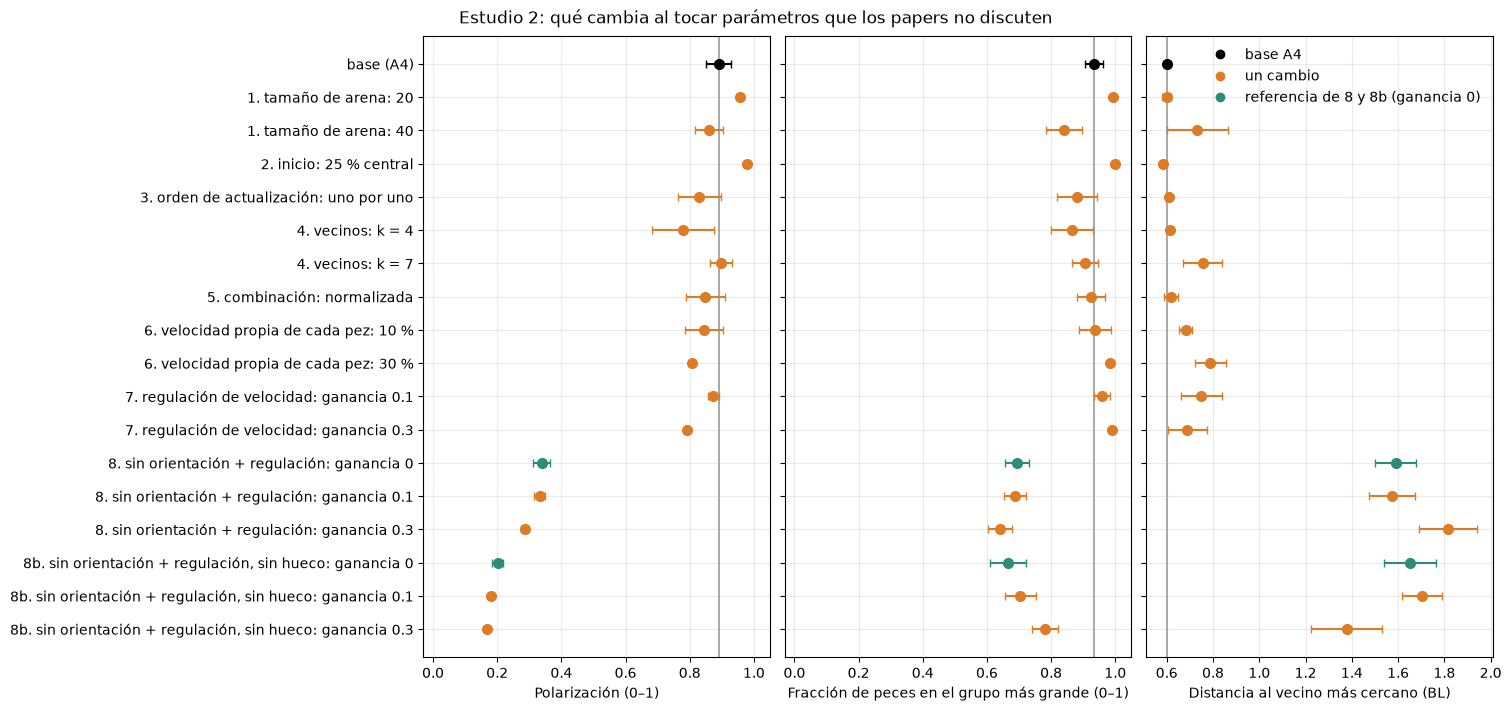

In [9]:
FIGURE_TITLE = "Estudio 2: qué cambia al tocar parámetros que los papers no discuten"

panels = [
    ("polarization", "Polarización (0–1)"),
    ("largest_group_fraction", "Fracción de peces en el grupo más grande (0–1)"),
    ("nnd", "Distancia al vecino más cercano (BL)"),
]
labels = list(summary["label"])
base_row = summary[summary["parameter"] == "base"].iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True, constrained_layout=True)
for axis, (column, axis_label) in zip(axes, panels):
    axis.axvline(base_row[column], color="0.6", linewidth=1.2, zorder=0)
    for index in range(len(summary)):
        row = summary.iloc[index]
        color = PUCKETT_COLOR
        if row["parameter"] == "base":
            color = "black"
        elif row["value"] == "ganancia 0":
            color = EXTRA_COLOR
        axis.errorbar(row[column], index, xerr=row[column + "_se"], color=color, marker="o",
                      markersize=7, capsize=3)
    axis.set_xlabel(axis_label)
    axis.grid(alpha=0.25)
    if column != "nnd":
        axis.set_xlim(-0.03, 1.05)
axes[0].set_yticks(list(range(len(labels))))
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()
# Legend for the three colours (empty plots only create the legend entries).
axes[2].plot([], [], "o", color="black", label="base A4")
axes[2].plot([], [], "o", color=PUCKETT_COLOR, label="un cambio")
axes[2].plot([], [], "o", color=EXTRA_COLOR, label="referencia de 8 y 8b (ganancia 0)")
axes[2].legend(frameon=False, loc="upper right")
fig.suptitle(FIGURE_TITLE)
fig.savefig(FIGURE_FOLDER / "study_02_parameters.png", dpi=150)
plt.show()

## Extra (no está en el README): ¿las seeds que fallan solo necesitan más tiempo?

En la base A4, las seeds que no funcionan terminan **separadas**. Con inicio compacto (parámetro 2) o arena más chica (parámetro 1) funcionan casi todas. Eso sugiere que el grupo no se rompe: simplemente **todavía no se juntó**. Para comprobarlo, corremos la misma base con el triple de nado (540 BL en vez de 180) y medimos, como siempre, el último tercio. La definición de "funciona" no cambia.

In [10]:
longer = change_settings(base, "base (A4), 540 BL de nado", {"swim_distance": 540.0})
longer_results = run_many([longer], SEEDS, DATA_FOLDER / "extra_longer_runs.csv")

# Seed by seed: does the school work after 180 BL and after 540 BL?
per_seed = pd.DataFrame({
    "seed": SEEDS,
    "works after 180 BL": results[results["label"] == "base (A4)"].sort_values("seed")["works"].to_numpy(),
    "works after 540 BL": longer_results.sort_values("seed")["works"].to_numpy(),
    "time together after 540 BL": longer_results.sort_values("seed")["together_fraction"].to_numpy(),
})
per_seed

[1/1] base (A4), 540 BL de nado: works in 10 of 10 seeds (0.8 min so far)


,seed,works after 180 BL,works after 540 BL,time together after 540 BL
0,0,True,True,1.0
1,1,True,True,1.0
2,2,False,True,1.0
3,3,False,True,1.0
4,4,False,True,1.0
5,5,True,True,1.0
6,6,True,True,1.0
7,7,True,True,1.0
8,8,False,True,1.0
9,9,True,True,1.0


## Guardar

Los resultados ya están en `data/results.csv` (una fila por simulación). Guardamos también la tabla de relevancia.

In [11]:
relevance.to_csv(DATA_FOLDER / "relevance.csv", index=False)
print("Saved data/relevance.csv")

Saved data/relevance.csv


## Conclusión

Ver las secciones "Resultados" y "Conclusión" del [README](README.md) de este estudio.